# Simple and multiple regression: energy, market and oil

This analysis uses monthly US energy-sector excess returns for **2011–2025**.
A market-only regression describes their relationship with the broad equity
market; a second specification adds changes in the Brent oil price.

The two models use the same observations. Coefficients, standard errors and
confidence intervals describe the estimated relationships and their uncertainty;
fitted values and residuals show how much return variation remains unexplained.

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorise Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.

In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "OLS"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: OLS


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display

## Data

- **Energy:** total return on the value-weighted US energy-sector portfolio from the
  [Kenneth French industry data](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_12_ind_port.html).
  It combines energy stocks, weighted by market capitalisation, rather than tracking
  one company. Total returns include dividends.
- **Market:** broad value-weighted US CRSP equity-market return minus RF (`Mkt-RF`),
  from the [French factor data](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_factors.html).
  This covers eligible US stocks on NYSE, AMEX and NASDAQ; it is not the S&P 500.
  **RF** is the matched monthly risk-free return, rather than an annualised yield.
- **Brent:** last available monthly [EIA/FRED spot price](https://fred.stlouisfed.org/series/DCOILBRENTEU).
  Its simple percentage change is an explanatory variable, not a futures return.

Subtract RF from Energy to obtain its excess return. Market is already an excess
return, so RF is not subtracted again. Returns are converted from decimals to
**percent**: a value of 1 means 1%, and a one-unit increase means one percentage point.

December 2010 supplies the initial Brent price. Both regressions use the following
**180 months**, January 2011 to December 2025. Month-end dates label the months;
the CSV also records the date of each Brent price actually used.

In [3]:
data = pd.read_csv(DATA_DIR / "monthly_energy_market_data.csv", parse_dates=["date"])
data = data.set_index("date").sort_index()

returns = pd.DataFrame({
    "Energy": 100 * (data["Energy"] - data["RF"]),
    "Market": 100 * data["Market_excess"],
    "Brent": 100 * data["Brent_spot"].pct_change(fill_method=None),
}).loc["2011-01-01":"2025-12-31"]

if returns.isna().any().any():
    raise ValueError("Missing observations: check the data before comparing the models.")
print(f"Estimation sample: {returns.index[0]:%Y-%m} to {returns.index[-1]:%Y-%m}; {len(returns)} months")
display(returns.head().round(3))

Estimation sample: 2011-01 to 2025-12; 180 months


,Energy,Market,Brent
date,,,
2011-01-31,6.92,1.98,6.157
2011-02-28,7.62,3.48,13.438
2011-03-31,2.10,0.45,4.160
2011-04-30,1.58,2.90,8.252
2011-05-31,-4.51,-1.27,-7.433


## Simple regression: the market model

$$r^e_{E,t}=\alpha+\beta_M r^e_{M,t}+u_t.$$

**Alpha** is fitted energy excess return when Market is zero. **Beta** is its change,
in percentage points, for a one-percentage-point increase in Market. For example,
a beta of 1.2 associates a 1 pp market increase with a 1.2 pp increase in fitted
energy return. This does not mean that every observed energy return follows that rule:
the residual is the difference between the observed and fitted return.

This CAPM-style regression uses a sector portfolio; CAPM reasoning also applies
to individual stocks. With an appropriate market portfolio and the CAPM assumptions,
the pricing restriction implies zero alpha. Estimating this regression alone does
not validate the CAPM.

Both models use OLS coefficients and **Newey–West HAC standard errors with three
monthly lags**. HAC allows heteroskedasticity and short-run serial dependence;
it changes estimated uncertainty, not coefficients or fitted values.

In [4]:
y = returns["Energy"]
# Newey–West HAC: Bartlett weights, three monthly lags and a sample-size correction.
# The t reference used for robust inference is an approximation, not an exact test.
HAC_OPTIONS = {"maxlags": 3, "kernel": "bartlett", "use_correction": True}

X_simple = sm.add_constant(returns[["Market"]])
simple = sm.OLS(y, X_simple, missing="raise").fit(
    cov_type="HAC", cov_kwds=HAC_OPTIONS, use_t=True
)
print(simple.summary())

                            OLS Regression Results                            
Dep. Variable:                 Energy   R-squared:                       0.401
Model:                            OLS   Adj. R-squared:                  0.398
Method:                 Least Squares   F-statistic:                     35.97
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           1.09e-08
Time:                        14:23:29   Log-Likelihood:                -577.72
No. Observations:                 180   AIC:                             1159.
Df Residuals:                     178   BIC:                             1166.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.6295      0.576     -1.093      0.2

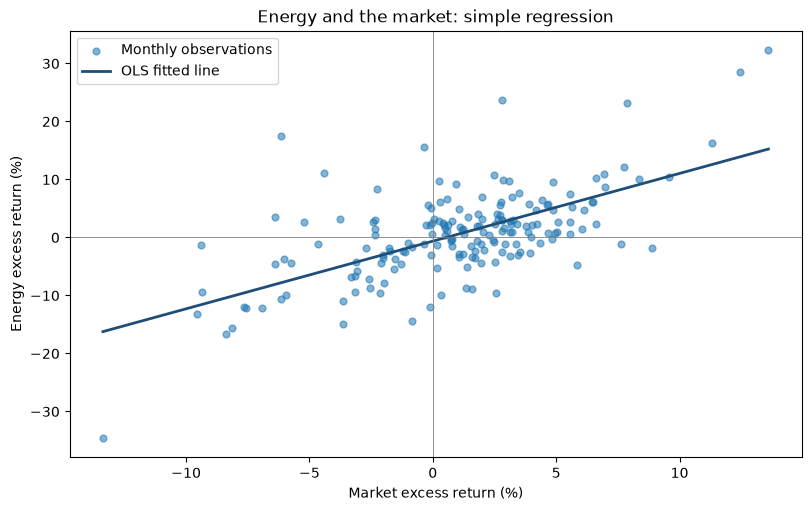

In [5]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.scatter(returns["Market"], y, s=24, alpha=0.55, label="Monthly observations")
market_grid = np.linspace(returns["Market"].min(), returns["Market"].max(), 100)
ax.plot(market_grid, simple.params["const"] + simple.params["Market"] * market_grid,
        color="#1F4E79", lw=2, label="OLS fitted line")
ax.axhline(0, color="grey", lw=0.6)
ax.axvline(0, color="grey", lw=0.6)
ax.set(xlabel="Market excess return (%)", ylabel="Energy excess return (%)",
       title="Energy and the market: simple regression")
ax.legend()
plt.show()

The **standard error** measures sampling uncertainty about a coefficient, not return
volatility or residual dispersion. A smaller standard error means a more precise
estimate. The reported statistic is $t=\hat\theta/SE(\hat\theta)$, testing
$H_0:\theta=0$ against $H_1:\theta\ne0$; for beta, this is not a test of beta = 1.

Under the null and test assumptions, the **p-value** is the probability of a statistic
at least as extreme as observed. It is not the probability that the null is true,
and it does not measure the size of the relationship. At 5%, reject when $p<0.05$;
non-rejection does not establish that the coefficient is zero. A Type I error is
rejecting a true null. A displayed `0.000` is rounding.

A **95% confidence-interval procedure** covers the true coefficient in 95% of repeated
samples under its assumptions. The interval excludes zero exactly when the matching
two-sided 5% test rejects. HAC inference is approximate; economic importance and
statistical significance remain separate considerations.

## Multiple regression: adding Brent

$$r^e_{E,t}=\alpha+\beta_M r^e_{M,t}+\beta_O\Delta p^{Brent}_t+u_t.$$

$\Delta p^{Brent}_t$ is the monthly percentage change in the spot price.
The market slope now measures the change in fitted Energy **holding Brent constant**;
the Brent slope holds Market constant. Alpha corresponds to both regressors being zero.

Market and oil-price movements can be related. Including both separates their
partial associations with energy returns, so the market slope need not equal its
estimate in the simple regression. Adding Brent gives an extended return regression,
rather than the one-factor CAPM. The coefficients do not by themselves establish
causal effects.

In [6]:
X_multiple = sm.add_constant(returns[["Market", "Brent"]])
multiple = sm.OLS(y, X_multiple, missing="raise").fit(
    cov_type="HAC", cov_kwds=HAC_OPTIONS, use_t=True
)
print(multiple.summary())

                            OLS Regression Results                            
Dep. Variable:                 Energy   R-squared:                       0.531
Model:                            OLS   Adj. R-squared:                  0.525
Method:                 Least Squares   F-statistic:                     50.03
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           6.01e-18
Time:                        14:23:32   Log-Likelihood:                -555.78
No. Observations:                 180   AIC:                             1118.
Df Residuals:                     177   BIC:                             1127.
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.4757      0.486     -0.979      0.3

### Interpreting the slopes

Rounded to three decimals, the fitted multiple regression is

$$\widehat r^e_E=-0.476+0.883\,r^e_M+0.246\,\Delta p^{Brent}.$$

The panels show fitted Energy as Market varies with Brent fixed at zero, and as
Brent varies with Market fixed at zero. A 1 pp increase contributes approximately
**0.883 pp** through Market or **0.246 pp** through Brent, holding the other fixed.
Both panels use the **same horizontal and vertical scales**, so their slopes can
also be compared visually. The plotted ranges are illustrative; estimation uses
all 180 months.

Both lines cross the vertical axis at **−0.476%** because both regressors are zero
at that point. Fixing Brent at another value $b$ would shift the Market line's
intercept to $\hat\alpha+\hat\beta_O b$, without changing its slope.
For example, with Brent fixed at 10%, fitted Energy at Market = 0 is approximately
**1.98%**. This is a fitted value, not a guaranteed realised return.

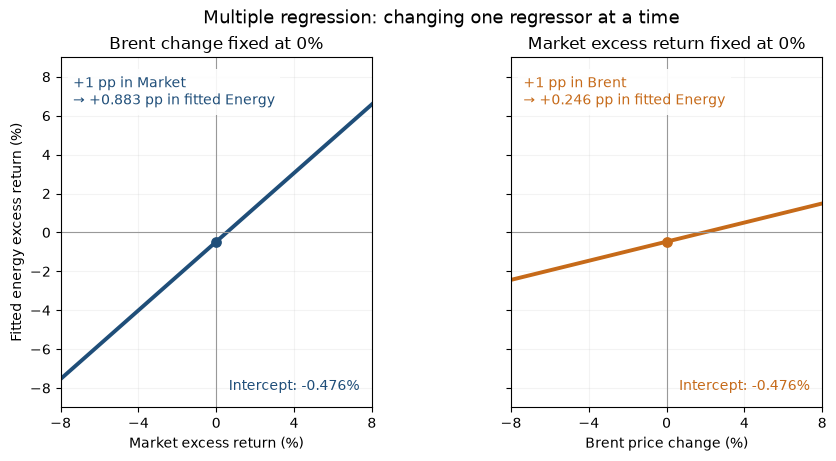

In [7]:
alpha = multiple.params["const"]
beta_market = multiple.params["Market"]
beta_brent = multiple.params["Brent"]
market_grid = np.linspace(-8, 8, 100)
brent_grid = market_grid.copy()
market_colour, brent_colour = "#1F4E79", "#C66A19"

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), sharex=True, sharey=True,
                         constrained_layout=True)
panels = [
    (axes[0], market_grid, alpha + beta_market * market_grid,
     market_colour, "Market excess return (%)", "Brent change fixed at 0%",
     beta_market, "Market"),
    (axes[1], brent_grid, alpha + beta_brent * brent_grid,
     brent_colour, "Brent price change (%)", "Market excess return fixed at 0%",
     beta_brent, "Brent"),
]
for ax, grid, fitted, colour, xlabel, title, beta, name in panels:
    ax.plot(grid, fitted, color=colour, lw=2.8)
    ax.scatter([0], [alpha], color=colour, s=45, zorder=3)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.axvline(0, color="0.6", lw=0.8)
    ax.grid(alpha=0.15)
    ax.set(xlabel=xlabel, title=title, xlim=(-8, 8), ylim=(-9, 9))
    ax.set_xticks([-8, -4, 0, 4, 8])
    ax.set_aspect("equal", adjustable="box")
    ax.text(0.04, 0.95, f"+1 pp in {name}\n→ {beta:+.3f} pp in fitted Energy",
            transform=ax.transAxes, va="top", fontsize=10, color=colour,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})
    ax.text(0.96, 0.05, f"Intercept: {alpha:.3f}%",
            transform=ax.transAxes, ha="right", color=colour, fontsize=10)
axes[0].set_ylabel("Fitted energy excess return (%)")
fig.suptitle("Multiple regression: changing one regressor at a time", fontsize=13)
plt.show()

### The regression plane

The same slopes appear in 3D: **blue** varies Market with Brent fixed at zero;
**orange** varies Brent with Market fixed at zero. The surface shows fitted returns.
Observations are omitted to keep the plane visible.

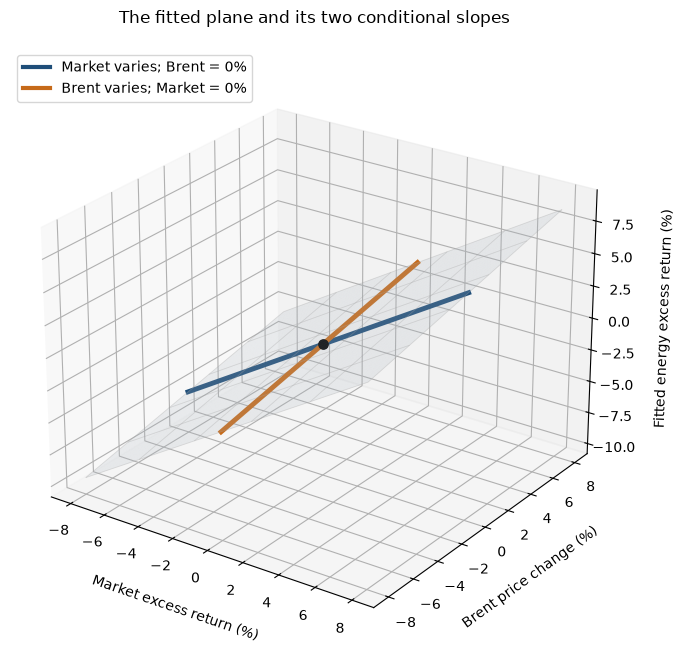

In [8]:
from matplotlib.lines import Line2D

market_mesh, brent_mesh = np.meshgrid(market_grid, brent_grid)
energy_mesh = alpha + beta_market * market_mesh + beta_brent * brent_mesh

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(market_mesh, brent_mesh, energy_mesh,
                color="#B9C4CE", alpha=0.20, linewidth=0)
ax.plot_wireframe(market_mesh, brent_mesh, energy_mesh,
                  rstride=20, cstride=20, color="0.65", alpha=0.35, linewidth=0.6)
ax.plot(market_grid, np.zeros_like(market_grid),
        alpha + beta_market * market_grid, color=market_colour, lw=3.5)
ax.plot(np.zeros_like(brent_grid), brent_grid,
        alpha + beta_brent * brent_grid, color=brent_colour, lw=3.5)
ax.scatter([0], [0], [alpha], color="black", s=45, depthshade=False)
ax.set_xlabel("Market excess return (%)", labelpad=10)
ax.set_ylabel("Brent price change (%)", labelpad=10)
ax.set_zlabel("Fitted energy excess return (%)", labelpad=10)
ax.set_title("The fitted plane and its two conditional slopes", pad=18)
ax.set_box_aspect((1.2, 1.2, 0.9))
ax.view_init(elev=25, azim=-55)
ax.legend(handles=[
    Line2D([], [], color=market_colour, lw=3, label="Market varies; Brent = 0%"),
    Line2D([], [], color=brent_colour, lw=3, label="Brent varies; Market = 0%"),
], loc="upper left", fontsize=10)
fig.subplots_adjust(left=0.02, right=0.87, bottom=0.05, top=0.92)
plt.show()

## Comparing the models

The table compares coefficients, HAC standard errors and fit on the same sample.
The residual standard deviation measures unexplained return variation, in
percentage points; it differs from a coefficient's standard error.

The plots compare **observed and fitted returns**. Multiple-model fitted values
use both Market and Brent. Points on the 45-degree line have observed return equal
to fitted return; their vertical distance from it is the residual.

In [9]:
models = {"Market only": simple, "Market + Brent": multiple}
comparison = pd.DataFrame({
    name: {"Observations": int(model.nobs),
           "Alpha (% per month)": model.params["const"],
           "Market beta": model.params["Market"],
           "SE: market beta": model.bse["Market"],
           "R-squared": model.rsquared,
           "Adjusted R-squared": model.rsquared_adj,
           "Residual SD (pp)": np.sqrt(model.mse_resid)}
    for name, model in models.items()
})
display(comparison.round(4))
print(f"Market–Brent sample correlation: {returns['Market'].corr(returns['Brent']):.3f}")

,Market only,Market + Brent
Observations,180.0000,180.0000
Alpha (% per month),-0.6295,-0.4757
Market beta,1.1672,0.8825
SE: market beta,0.1946,0.1787
R-squared,0.4010,0.5306
Adjusted R-squared,0.3977,0.5253
Residual SD (pp),6.0268,5.3503


Market–Brent sample correlation: 0.394


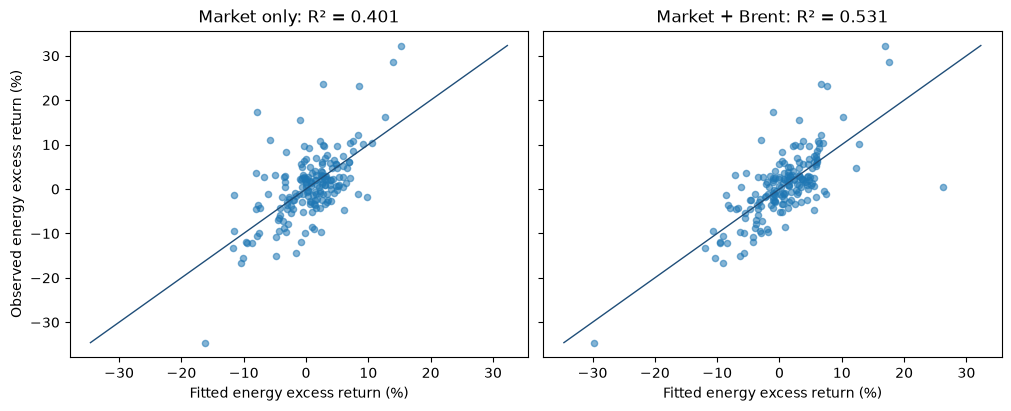

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True,
                         constrained_layout=True)
limits = [min(y.min(), *(m.fittedvalues.min() for m in models.values())),
          max(y.max(), *(m.fittedvalues.max() for m in models.values()))]
for ax, (name, model) in zip(axes, models.items()):
    ax.scatter(model.fittedvalues, y, s=20, alpha=0.55)
    ax.plot(limits, limits, color="#1F4E79", lw=1)
    ax.set(title=f"{name}: R² = {model.rsquared:.3f}",
           xlabel="Fitted energy excess return (%)")
axes[0].set_ylabel("Observed energy excess return (%)")
plt.show()

$R^2$ is the fraction of sample return variation explained by the model with an
intercept. Adding Brent cannot lower in-sample $R^2$ on the same sample;
adjusted $R^2$ penalises extra regressors and need not increase. Better fit does
not establish causality or guarantee better forecasts.

Brent's association with Energy and correlation with Market help explain the change
in market beta, linking the comparison to **omitted variable bias**. A changed
coefficient alone does not show that the multiple model identifies a causal effect.
HAC standard errors do not remove this bias; robust inference is examined in a later
tutorial.